# Red neuronal (MLP) para estimar el area cosechada — EVA Colombia

**Inteligencia Artificial I — Grupo C2, Periodo 2026-2**
**Modelo de este notebook:** Red neuronal (`MLPRegressor` de scikit-learn)

Este notebook es uno de los 4 modelos del equipo (Decision Tree, Random Forest, Red neuronal y SVR). Para que los 4 se puedan unir despues, usa **exactamente** la limpieza y el bloque comun acordados.

## Orden de las celdas (ejecutar de arriba hacia abajo, sin saltarse ninguna)
1. Librerias
2. Limpieza (tabla `datos`)
3. Bloque comun (features, division por anios, metricas)
4. **PASO M1:** probar 9 combinaciones de hiperparametros (entrena 2007-2021, mide en 2022)
5. **PASO M1b:** revisar la estabilidad de la red con 3 semillas
6. **PASO M2:** modelo final (entrena 2007-2022) y prueba UNA sola vez (2023-2025)
7. **PASO M3:** graficos para el informe

Al final se guardan 3 archivos en la carpeta EVA de Drive para unir los 4 notebooks.

In [ ]:
# =========================================================
# Librerias que vamos a usar
# =========================================================
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

print("Librerias cargadas")

Librerias cargadas


---
# Limpieza de los archivos EVA

Codigo definitivo acordado por el equipo (no se modifica). Produce la tabla `datos`.

In [ ]:
# =====================================================================
# LIMPIEZA DEFINITIVA DE LOS ARCHIVOS EVA (2007-2018 y 2019-2025)
# Resultado: la tabla "datos" con UNA fila por municipio + cultivo +
# estado fisico + anio, lista para entrenar los modelos.
# =====================================================================

import pandas as pd
import numpy as np

# =========================================================
# PASO 1: Cargar los dos archivos desde Google Drive
# =========================================================
print("PASO 1: Cargar los dos archivos desde Google Drive")
# Los archivos deben estar guardados en:  MiUnidad / EVA /
from google.colab import drive
drive.mount("/content/drive")

RUTA = "/content/drive/MyDrive/EVA/"

# Leemos todo como texto: los numeros vienen en formato colombiano
# ("1.247.206,27") y los codigos DANE tienen ceros a la izquierda ("05001").
eva_viejo = pd.read_csv(RUTA + "EVA_2007_2018.csv", dtype=str)
eva_nuevo = pd.read_csv(RUTA + "EVA_2019_2025.csv", dtype=str)

print("EVA 2007-2018:", eva_viejo.shape[0], "filas y", eva_viejo.shape[1], "columnas")
print("EVA 2019-2025:", eva_nuevo.shape[0], "filas y", eva_nuevo.shape[1], "columnas")
print("PASO 1: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
# =========================================================
print("PASO 2: Dejar solo las columnas necesarias, con el mismo nombre")

# El archivo viejo trae saltos de linea dentro de los nombres
# ("Área Sembrada\n(ha)"): los cambiamos por un espacio.
eva_viejo.columns = [" ".join(nombre.split()) for nombre in eva_viejo.columns]
eva_nuevo.columns = [" ".join(nombre.split()) for nombre in eva_nuevo.columns]

# Solo columnas que existen en LOS DOS archivos y que se usan despues.
# (El rendimiento no se carga: se recalcula al final con la formula.)
nombres_nuevo = {
    "Código Dane departamento":  "cod_dep",
    "Departamento":              "departamento",
    "Código Dane municipio":     "cod_mun",
    "Municipio":                 "municipio",
    "Grupo cultivo":             "grupo",
    "Cultivo":                   "cultivo",
    "Desagregación cultivo":     "desagregacion",
    "Año":                       "anio",
    "Periodo":                   "periodo",
    "Área sembrada":             "area_sembrada",
    "Área cosechada":            "area_cosechada",
    "Producción":                "produccion",
    "Ciclo del cultivo":         "ciclo",
    "Estado físico del cultivo": "estado_fisico",
}
nombres_viejo = {
    "CÓD. DEP.":                                     "cod_dep",
    "DEPARTAMENTO":                                  "departamento",
    "CÓD. MUN.":                                     "cod_mun",
    "MUNICIPIO":                                     "municipio",
    "GRUPO DE CULTIVO":                              "grupo",
    "CULTIVO":                                       "cultivo",
    "DESAGREGACIÓN REGIONAL Y/O SISTEMA PRODUCTIVO": "desagregacion",
    "AÑO":                                           "anio",
    "PERIODO":                                       "periodo",
    "Área Sembrada (ha)":                            "area_sembrada",
    "Área Cosechada (ha)":                           "area_cosechada",
    "Producción (t)":                                "produccion",
    "CICLO DE CULTIVO":                              "ciclo",
    "ESTADO FISICO PRODUCCION":                      "estado_fisico",
}
COLUMNAS = list(nombres_nuevo.values())
eva_nuevo = eva_nuevo.rename(columns=nombres_nuevo)[COLUMNAS].copy()
eva_viejo = eva_viejo.rename(columns=nombres_viejo)[COLUMNAS].copy()

print("Columnas que se conservan:", COLUMNAS)
print("PASO 2: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 3: Convertir los numeros y los codigos DANE
# =========================================================
print("PASO 3: Convertir los numeros y los codigos DANE")

def convertir_a_numero(columna):
    # "1.247.206,27" -> 1247206.27  (el punto separa miles, la coma es decimal)
    texto = columna.str.replace(".", "", regex=False).str.replace(",", ".", regex=False)
    return pd.to_numeric(texto, errors="coerce")

for df in (eva_viejo, eva_nuevo):
    for columna in ["anio", "area_sembrada", "area_cosechada", "produccion"]:
        df[columna] = convertir_a_numero(df[columna])
    df["anio"] = df["anio"].astype(int)
    # Codigos: "15.114" -> "15114"  y  "5.001" -> "05001"
    df["cod_dep"] = df["cod_dep"].str.replace(".", "", regex=False).str.zfill(2)
    df["cod_mun"] = df["cod_mun"].str.replace(".", "", regex=False).str.zfill(5)

# Controles: ningun numero vacio, ningun negativo, codigos coherentes
for nombre, df in [("2007-2018", eva_viejo), ("2019-2025", eva_nuevo)]:
    numeros = df[["area_sembrada", "area_cosechada", "produccion"]]
    assert numeros.notna().all().all(), "Hay numeros que no se pudieron convertir en " + nombre
    assert (numeros >= 0).all().all(), "Hay numeros negativos en " + nombre
    assert (df["cod_mun"].str[:2] == df["cod_dep"]).all(), "Codigos inconsistentes en " + nombre

print("PASO 3: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 4: Poner el texto en mayusculas y sin tildes
# =========================================================
print("PASO 4: Poner el texto en mayusculas y sin tildes")

def limpiar_texto(columna):
    texto = columna.str.upper().str.strip()
    texto = texto.str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("utf-8")
    return texto.str.replace(r"\s+", " ", regex=True)   # espacios dobles -> uno

for df in (eva_viejo, eva_nuevo):
    for columna in ["departamento", "municipio", "grupo", "cultivo",
                    "desagregacion", "ciclo", "estado_fisico"]:
        df[columna] = limpiar_texto(df[columna])

print("PASO 4: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 5: Estandarizar los nombres de cultivo y de estado fisico
# =========================================================
# Regla: solo se unifica lo que es el MISMO cultivo. Lo que es distinto
# se deja separado, y si queda solo en un archivo se elimina en el PASO 6.
print("PASO 5: Estandarizar los nombres de cultivo y de estado fisico")

# 5.1 El archivo nuevo junta las tres canas en "CANA", pero la desagregacion
#     las separa. Como son productos distintos, las separamos igual que el viejo.
es_cana = eva_nuevo["cultivo"] == "CANA"
eva_nuevo.loc[es_cana, "cultivo"] = eva_nuevo.loc[es_cana, "desagregacion"]
eva_nuevo["cultivo"] = eva_nuevo["cultivo"].replace({"CANA DE AZUCAR": "CANA AZUCARERA",
                                                     "ESTEVIA": "STEVIA"})

# 5.2 Nombres del archivo viejo que se pasan al nombre del archivo nuevo.
cultivos_equivalentes = {
    # a) El mismo cultivo, solo cambio el nombre
    "DURAZNO":     "DURAZNO O ALBARICOQUE",
    "AGRAZ":       "AGRAZ - MORTINO",
    "PEPA DE PAN": "ARBOL DE PAN O PEPA DEL PAN",
    "PAPAYUELA":   "PAPAYUELA -BABACO",
    "CURCUMA":     "CURCUMA O AZAFRAN",
    "RUBA":        "ULLUCO",
    # b) El archivo nuevo definio una categoria que junta exactamente
    #    los cultivos que el viejo traia separados
    "GULUPA":      "GULUPA O CHOLUPA",
    "CHOLUPA":     "GULUPA O CHOLUPA",
    "CALABACIN":   "CALABACIN, CALABAZA",
    "CALABAZA":    "CALABACIN, CALABAZA",
    "MALANGA":     "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
    "BORE":        "MALANGA, ACHIN, YOTA, PAPA CHINA, BORE",
}
eva_viejo["cultivo"] = eva_viejo["cultivo"].replace(cultivos_equivalentes)

# 5.3 Estado fisico: se unifican solo los nombres que significan lo mismo.
#     Lo demas se deja como viene (ej. PANELA y CANA O VERDE son distintos).
estados_equivalentes = {
    "FRUTO FRESCO":       "EN FRESCO",
    "HORTALIZA FRESCA":   "EN FRESCO",
    "TUBERCULO FRESCO":   "EN FRESCO",
    "HOJA FRESCA":        "EN FRESCO",
    "LEGUMINOSA FRESCA":  "EN FRESCO",
    "PADDY VERDE":        "PADDY O CASCARA VERDE",
    "SEMILLA":            "ALGODON SEMILLA",
    "CANA PARA MOLIENDA": "CANA O VERDE",
}
eva_viejo["estado_fisico"] = eva_viejo["estado_fisico"].replace(estados_equivalentes)

print("PASO 5: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos
# =========================================================
print("PASO 6: Mismo grupo y ciclo para cada cultivo, y solo cultivos de ambos archivos")

# 6.1 Nos quedamos solo con los cultivos que aparecen en LOS DOS archivos
cultivos_comunes = set(eva_viejo["cultivo"]) & set(eva_nuevo["cultivo"])
eliminados = (pd.concat([eva_viejo, eva_nuevo])
                .loc[lambda df: ~df["cultivo"].isin(cultivos_comunes)]
                .groupby("cultivo")["area_cosechada"].sum()
                .sort_values(ascending=False))
print("Cultivos que estan en un solo archivo (se eliminan):", len(eliminados))
print("Los 10 con mas area cosechada:")
print(eliminados.head(10).round(0))

eva_viejo = eva_viejo[eva_viejo["cultivo"].isin(cultivos_comunes)].copy()
eva_nuevo = eva_nuevo[eva_nuevo["cultivo"].isin(cultivos_comunes)].copy()

# 6.2 Catalogo: grupo y ciclo de cada cultivo segun el archivo nuevo
#     (ahi cada cultivo tiene un solo grupo y un solo ciclo)
catalogo = eva_nuevo.groupby("cultivo")[["grupo", "ciclo"]].first()
assert (eva_nuevo.groupby("cultivo")["grupo"].nunique() == 1).all()
assert (eva_nuevo.groupby("cultivo")["ciclo"].nunique() == 1).all()

# 6.3 El archivo viejo toma el grupo y el ciclo del catalogo
eva_viejo["grupo"] = eva_viejo["cultivo"].map(catalogo["grupo"])
eva_viejo["ciclo"] = eva_viejo["cultivo"].map(catalogo["ciclo"])

print("Cultivos que quedan:", len(cultivos_comunes))
print("Grupos:", sorted(catalogo["grupo"].unique()))
print("PASO 6: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018
# =========================================================
print("PASO 7: Unir los dos archivos y quitar los anios 2006 y 2018")

eva_viejo["fuente"] = "2007-2018"
eva_nuevo["fuente"] = "2019-2025"
datos = pd.concat([eva_viejo, eva_nuevo], ignore_index=True)

# Nombres oficiales a partir del codigo DANE (se usa el del archivo nuevo).
# Asi un municipio no aparece con dos nombres ("DON MATIAS" / "DONMATIAS").
for codigo, nombre in [("cod_dep", "departamento"), ("cod_mun", "municipio")]:
    nombre_oficial = datos.sort_values("fuente").groupby(codigo)[nombre].last()
    datos[nombre] = datos[codigo].map(nombre_oficial)

# 2006: solo trae el semestre B.  2018: no trae el semestre B.
# Los dos anios estan incompletos y sesgarian los totales anuales.
print("Filas del 2006:", (datos["anio"] == 2006).sum())
print("Filas del 2018:", (datos["anio"] == 2018).sum())
datos = datos[~datos["anio"].isin([2006, 2018])]

print("Filas despues de unir:", len(datos))
print("PASO 7: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 8: Pasar de semestres a anios (suma simple)
# =========================================================
# Se suman los semestres A y B y las variedades (desagregaciones) de cada
# cultivo. La produccion solo se suma entre filas con el MISMO estado fisico,
# por eso el estado fisico es parte de la clave (ej. maiz en grano seco y
# maiz en fresco quedan en filas separadas).
print("PASO 8: Pasar de semestres a anios (suma simple)")

CLAVE = ["cod_mun", "cultivo", "estado_fisico", "anio"]
datos = (datos.groupby(CLAVE, as_index=False)
              .agg(fuente=("fuente", "first"),
                   cod_dep=("cod_dep", "first"),
                   departamento=("departamento", "first"),
                   municipio=("municipio", "first"),
                   grupo=("grupo", "first"),
                   ciclo=("ciclo", "first"),
                   area_sembrada=("area_sembrada", "sum"),
                   area_cosechada=("area_cosechada", "sum"),
                   produccion=("produccion", "sum")))

# Rendimiento recalculado con la formula (vacio si no hubo cosecha)
datos["rendimiento"] = np.where(datos["area_cosechada"] > 0,
                                datos["produccion"] / datos["area_cosechada"], np.nan)

print("Filas anuales:", len(datos))
print("PASO 8: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 9: Regla de arrastre (sin tolerancia) y consistencia
# =========================================================
# En los cultivos TRANSITORIOS, lo sembrado y no cosechado un anio puede
# cosecharse al anio siguiente (solo se arrastra UN anio):
#     area_pendiente_anterior = sembrada(anio-1) - cosechada(anio-1)   (si es > 0)
#     area_disponible         = sembrada(anio) + area_pendiente_anterior
# En los PERMANENTES no hay arrastre (el area sembrada ya es todo lo plantado).
# Se elimina toda fila que coseche mas que el area disponible.
print("PASO 9: Regla de arrastre (sin tolerancia) y consistencia")

datos = datos.sort_values(CLAVE).reset_index(drop=True)
serie = datos.groupby(["cod_mun", "cultivo", "estado_fisico"])
sembrada_ant = serie["area_sembrada"].shift(1)
cosechada_ant = serie["area_cosechada"].shift(1)
anio_ant = serie["anio"].shift(1)

# Solo hay arrastre si existe el anio inmediatamente anterior y es transitorio
hay_arrastre = (datos["anio"] - anio_ant == 1) & (datos["ciclo"] == "TRANSITORIO")
datos["area_pendiente_anterior"] = np.where(hay_arrastre,
                                            (sembrada_ant - cosechada_ant).clip(lower=0), 0.0)
area_disponible = datos["area_sembrada"] + datos["area_pendiente_anterior"]

regla_arrastre = datos["area_cosechada"] > area_disponible        # cosecho mas de lo disponible
regla_produccion = (datos["produccion"] > 0) & (datos["area_cosechada"] == 0)   # produccion sin cosecha
sin_area = area_disponible == 0                                    # nada sembrado ni pendiente

print("Cosecharon mas que el area disponible:", regla_arrastre.sum())
print("Produccion sin area cosechada        :", regla_produccion.sum())
print("Sin area sembrada ni pendiente       :", sin_area.sum())
datos = datos[~(regla_arrastre | regla_produccion | sin_area)].reset_index(drop=True)

print("Filas que quedan:", len(datos))
print("PASO 9: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 10: Agregar la altura de cada municipio (msnm)
# =========================================================
# Fuente: IGAC, publicada en el Panel Municipal del CEDE (Universidad de los
# Andes), archivo "PANEL_CARACTERISTICAS_GENERALES_2021.csv" guardado en la
# misma carpeta de Drive. Columnas usadas: codmpio (codigo DANE) y altura (msnm).
print("PASO 10: Agregar la altura de cada municipio (msnm)")

ARCHIVO_ALTURA = RUTA + "PANEL_CARACTERISTICAS_GENERALES_2021.csv"
altura = pd.read_csv(ARCHIVO_ALTURA, usecols=["codmpio", "altura"], encoding="latin-1")

# El panel trae una fila por anio, pero la altura de un municipio no cambia:
# nos quedamos con una sola fila por municipio.
altura = altura.dropna(subset=["altura"]).drop_duplicates(subset="codmpio")
altura["cod_mun"] = altura["codmpio"].astype(int).astype(str).str.zfill(5)   # 5001 -> "05001"
altura = altura.rename(columns={"altura": "altura_msnm"})[["cod_mun", "altura_msnm"]]

# Municipios que no estan en el panel (creados despues): altura aproximada a mano
altura_manual = pd.DataFrame({
    "cod_mun":     ["27493"],     # NUEVO BELEN DE BAJIRA (Choco)
    "altura_msnm": [105],
})
altura = pd.concat([altura, altura_manual], ignore_index=True)

datos = datos.merge(altura, on="cod_mun", how="left")

print("PASO 10: Ejecutado correctamente")
print("-------------------------------")

# =========================================================
# PASO 11: Revision final y orden de columnas
# =========================================================
print("PASO 11: Revision final y orden de columnas")

# La clave debe ser unica: una fila por municipio + cultivo + estado + anio
assert not datos.duplicated(CLAVE).any(), "Hay filas repetidas en la clave"

COLUMNAS_FINALES = ["anio", "fuente", "cod_dep", "departamento", "cod_mun", "municipio",
                    "altura_msnm", "grupo", "cultivo", "ciclo", "estado_fisico",
                    "area_sembrada", "area_pendiente_anterior", "area_cosechada",
                    "produccion", "rendimiento"]
datos = datos[COLUMNAS_FINALES]

print("Filas:", len(datos), "| Columnas:", datos.shape[1])
print("Anios:", sorted(datos["anio"].unique()))
print("Departamentos:", datos["cod_dep"].nunique(), "| Municipios:", datos["cod_mun"].nunique(),
      "| Cultivos:", datos["cultivo"].nunique(), "| Grupos:", datos["grupo"].nunique())
print()
print("Datos faltantes por columna:")
print(datos.isna().sum()[datos.isna().sum() > 0])
print("(el rendimiento queda vacio solo cuando el area cosechada es 0)")
print()
print("Filas por grupo y archivo:")
print(pd.crosstab(datos["grupo"], datos["fuente"]))
print()
# Cultivos cuyo estado fisico cambia entre archivos (su produccion no se compara)
estados = datos.groupby(["cultivo", "fuente"])["estado_fisico"].apply(lambda s: " / ".join(sorted(s.unique())))
estados = estados.unstack()
cambian = estados[estados["2007-2018"] != estados["2019-2025"]]
print("Cultivos cuyo estado fisico cambia entre archivos:", len(cambian))
print(cambian)
print("PASO 11: Ejecutado correctamente")
print("-------------------------------")

# Para guardar (al leerlo de nuevo, usar dtype={"cod_dep": str, "cod_mun": str}):
# datos.to_csv(RUTA + "eva_limpio.csv", index=False, encoding="utf-8-sig")

datos.head()


PASO 1: Cargar los dos archivos desde Google Drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EVA 2007-2018: 206068 filas y 17 columnas
EVA 2019-2025: 166732 filas y 18 columnas
PASO 1: Ejecutado correctamente
-------------------------------
PASO 2: Dejar solo las columnas necesarias, con el mismo nombre
Columnas que se conservan: ['cod_dep', 'departamento', 'cod_mun', 'municipio', 'grupo', 'cultivo', 'desagregacion', 'anio', 'periodo', 'area_sembrada', 'area_cosechada', 'produccion', 'ciclo', 'estado_fisico']
PASO 2: Ejecutado correctamente
-------------------------------
PASO 3: Convertir los numeros y los codigos DANE
PASO 3: Ejecutado correctamente
-------------------------------
PASO 4: Poner el texto en mayusculas y sin tildes
PASO 4: Ejecutado correctamente
-------------------------------
PASO 5: Estandarizar los nombres de cultivo y de estado fisico
PASO 5: Ejecutado correctamente
------------

,anio,fuente,cod_dep,departamento,cod_mun,municipio,altura_msnm,grupo,cultivo,ciclo,estado_fisico,area_sembrada,area_pendiente_anterior,area_cosechada,produccion,rendimiento
0,2007,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,1475.0,FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.0,0.0,0.0,0.0,NaN
1,2008,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,1475.0,FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,10.0,0.0,0.0,0.0,NaN
2,2009,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,1475.0,FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,12.0,0.0,6.0,36.0,6.0
3,2010,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,1475.0,FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,16.0,0.0,10.0,60.0,6.0
4,2011,2007-2018,05,ANTIOQUIA,05001,MEDELLIN,1475.0,FRUTALES,AGUACATE,PERMANENTE,EN FRESCO,19.0,0.0,16.0,96.0,6.0


---
# Bloque comun

Features, division por anios, metricas y funciones compartidas por los 4 notebooks (no se modifica).

In [ ]:
# =====================================================================
# BLOQUE COMUN PARA LOS 4 NOTEBOOKS (Decision Tree, Random Forest, MLP, SVR)
# Se ejecuta DESPUES de la limpieza (la tabla "datos" ya existe).
# Todos los notebooks deben usar este mismo bloque sin cambios.
# =====================================================================
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 42
ANIO_FIN_ENTRENO = 2021      # entrenamiento: 2007-2021 (sin 2018)
ANIO_VALIDACION = 2022       # validacion: elegir hiperparametros
ANIOS_PRUEBA = [2023, 2024, 2025]   # prueba: se evalua UNA sola vez al final

# ---------------------------------------------------------
# A) Variables del pasado (cada serie = municipio + cultivo + estado fisico)
# ---------------------------------------------------------
SERIE = ["cod_mun", "cultivo", "estado_fisico"]
df = datos.sort_values(SERIE + ["anio"]).reset_index(drop=True)

df["area_disponible"] = df["area_sembrada"] + df["area_pendiente_anterior"]

serie = df.groupby(SERIE)
anio_ant = serie["anio"].shift(1)
df["hay_ant"] = ((df["anio"] - anio_ant) == 1).astype(int)          # 1 si existe el anio anterior
df["cosechada_ant"] = np.where(df["hay_ant"] == 1, serie["area_cosechada"].shift(1), 0)
df["sembrada_ant"] = np.where(df["hay_ant"] == 1, serie["area_sembrada"].shift(1), 0)

# Tasa historica: promedio de (cosechada / disponible) de los anios ANTERIORES
df["tasa_real"] = df["area_cosechada"] / df["area_disponible"]
df["tasa_hist"] = serie["tasa_real"].transform(lambda s: s.shift(1).expanding().mean())
df["hay_hist"] = df["tasa_hist"].notna().astype(int)

# Variables simples
df["permanente"] = (df["ciclo"] == "PERMANENTE").astype(int)
df["rep2019"] = (df["fuente"] == "2019-2025").astype(int)

# Logaritmos: las areas van de 0,5 ha a 100.000 ha
for col in ["area_sembrada", "area_disponible", "cosechada_ant", "sembrada_ant"]:
    df["log_" + col] = np.log1p(df[col])

# ---------------------------------------------------------
# B) Division por anios
# ---------------------------------------------------------
entreno = df[df["anio"] <= ANIO_FIN_ENTRENO].copy()
validacion = df[df["anio"] == ANIO_VALIDACION].copy()
prueba = df[df["anio"].isin(ANIOS_PRUEBA)].copy()
print("Entrenamiento:", len(entreno), "| Validacion:", len(validacion), "| Prueba:", len(prueba))

# ---------------------------------------------------------
# C) Matriz de features (X) y variable objetivo (y)
#    Todo lo que se "aprende" de los datos sale SOLO del conjunto de entrenamiento.
# ---------------------------------------------------------
NUMERICAS = ["log_area_sembrada", "log_area_disponible", "log_cosechada_ant", "log_sembrada_ant",
             "hay_ant", "tasa_hist", "hay_hist", "altura_msnm", "anio", "rep2019", "permanente"]

def tasa_hist_completa(tabla_entreno, tabla):
    """Tasa historica; si falta, se usa el promedio del cultivo (o general) en entrenamiento."""
    tasa_cultivo = tabla_entreno.groupby("cultivo")["tasa_real"].mean()
    tasa = tabla["tasa_hist"].fillna(tabla["cultivo"].map(tasa_cultivo))
    return tasa.fillna(tabla_entreno["tasa_real"].mean())

def construir_X(tabla_entreno, tabla):
    """Devuelve la matriz X de 'tabla' usando las reglas aprendidas de 'tabla_entreno'."""
    t = tabla.copy()
    # 1) Tasa historica faltante -> promedio del cultivo en entrenamiento
    t["tasa_hist"] = tasa_hist_completa(tabla_entreno, t)
    # 2) Cultivos con menos de 100 filas de entrenamiento -> "OTROS"
    conteo = tabla_entreno["cultivo"].value_counts()
    cultivos_ok = conteo[conteo >= 100].index
    t["cultivo_mod"] = np.where(t["cultivo"].isin(cultivos_ok), t["cultivo"], "OTROS")
    # 3) One-hot con las categorias del entrenamiento (mismas columnas siempre)
    X = t[NUMERICAS].astype(float)
    for columna, categorias in [("grupo", sorted(tabla_entreno["grupo"].unique())),
                                ("cultivo_mod", sorted(set(cultivos_ok) | {"OTROS"})),
                                ("cod_dep", sorted(tabla_entreno["cod_dep"].unique()))]:
        for cat in categorias[1:]:          # se omite la primera categoria (referencia)
            X[columna + "_" + cat] = (t[columna] == cat).astype(float)
    return X

def objetivo(tabla):
    return np.log1p(tabla["area_cosechada"].values)          # el modelo aprende log(1 + area)

def a_hectareas(pred_log, tabla):
    # Volver a hectareas y no pasar del area disponible (no se cosecha mas de lo que hay)
    return np.clip(np.expm1(pred_log), 0, tabla["area_disponible"].values)

# ---------------------------------------------------------
# D) Metricas (iguales para los 4 modelos)
# ---------------------------------------------------------
def metricas(real, estimada):
    return {"WAPE_%": np.abs(real - estimada).sum() / real.sum() * 100,
            "MAE_ha": mean_absolute_error(real, estimada),
            "RMSE_ha": np.sqrt(mean_squared_error(real, estimada)),
            "R2": r2_score(real, estimada)}

def tabla_resultados(tabla_entreno, tabla, estimada, nombre_modelo):
    """Tabla con resultados del modelo y de las dos reglas base, total y por grupo."""
    filas = []
    tasa = tasa_hist_completa(tabla_entreno, tabla)
    reglas = {nombre_modelo: estimada,
              "Base: cosechada = sembrada": tabla["area_sembrada"].values,
              "Base: disponible x tasa historica": (tabla["area_disponible"] * tasa).values}
    for nombre, est in reglas.items():
        filas.append({"modelo": nombre, "grupo": "TOTAL", **metricas(tabla["area_cosechada"].values, est)})
        for g in sorted(tabla["grupo"].unique()):
            m = (tabla["grupo"] == g).values
            filas.append({"modelo": nombre, "grupo": g, **metricas(tabla["area_cosechada"].values[m], est[m])})
    return pd.DataFrame(filas)

def tabla_predicciones(tabla, estimada, nombre_modelo):
    """Predicciones en formato comun para unir los 4 notebooks."""
    salida = tabla[["anio", "cod_mun", "municipio", "departamento", "grupo", "cultivo",
                    "estado_fisico", "area_sembrada", "area_disponible", "area_cosechada"]].copy()
    salida["area_cosechada_estimada"] = estimada
    # Tasa de cosecha efectiva (%) = cosechada / sembrada x 100
    sembrada = salida["area_sembrada"].replace(0, np.nan)
    salida["tasa_cosecha_real_%"] = salida["area_cosechada"] / sembrada * 100
    salida["tasa_cosecha_estimada_%"] = salida["area_cosechada_estimada"] / sembrada * 100
    salida["modelo"] = nombre_modelo
    return salida

# Matrices listas para usar en cada notebook
X_entreno = construir_X(entreno, entreno)
X_validacion = construir_X(entreno, validacion)
y_entreno = objetivo(entreno)
print("Features:", X_entreno.shape[1])


Entrenamiento: 176975 | Validacion: 15041 | Prueba: 46334


/tmp/ipykernel_1108/3030662173.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_1108/3030662173.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_1108/3030662173.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) in

Features: 147


/tmp/ipykernel_1108/3030662173.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_1108/3030662173.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_1108/3030662173.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) in

---
# PASO M1 — Probar hiperparametros

La red neuronal **necesita variables escaladas** (si no, las columnas con numeros grandes como `altura_msnm` o `anio` dominan el entrenamiento). Por eso se usa un `StandardScaler` **ajustado solo con el entrenamiento** de cada etapa.

Se prueban 9 combinaciones (3 arquitecturas x 3 valores de `alpha`, la regularizacion). Se entrena con 2007-2021 y se mide en 2022. Fijos: `learning_rate_init=0.001`, `early_stopping=True`, `max_iter=300`, `random_state=42`.

> Puede tardar varios minutos en total (la arquitectura `(128, 64)` es la mas lenta).

In [ ]:
# =========================================================
# PASO M1: Probar hiperparametros (entrena 2007-2021, mide en 2022)
# =========================================================
print("PASO M1: Probar hiperparametros")

NOMBRE_MODELO = "Red neuronal (MLP)"

# Escalado OBLIGATORIO: el escalador se ajusta SOLO con el entrenamiento
escalador = StandardScaler().fit(X_entreno)
X_entreno_esc = escalador.transform(X_entreno)
X_validacion_esc = escalador.transform(X_validacion)

# Referencia: la regla simple "cosechada = sembrada" en validacion
wape_regla = metricas(validacion["area_cosechada"].values, validacion["area_sembrada"].values)["WAPE_%"]
print("WAPE de la regla 'cosechada = sembrada' en validacion:", round(wape_regla, 2), "%")
print()

combinaciones = []                                      # lista de diccionarios de hiperparametros
for capas in [(32,), (64, 32), (128, 64)]:
    for alpha in [0.0001, 0.001, 0.01]:
        combinaciones.append({"hidden_layer_sizes": capas, "alpha": alpha})

pruebas = []
for params in combinaciones:
    inicio = time.time()
    modelo = MLPRegressor(learning_rate_init=0.001, early_stopping=True, max_iter=300,
                          random_state=SEMILLA, **params)
    modelo.fit(X_entreno_esc, y_entreno)
    estimada = a_hectareas(modelo.predict(X_validacion_esc), validacion)
    resultado = metricas(validacion["area_cosechada"].values, estimada)
    pruebas.append({**params, **resultado})
    print(params, "-> WAPE:", round(resultado["WAPE_%"], 2), "% | iteraciones:", modelo.n_iter_,
          "| segundos:", round(time.time() - inicio))

pruebas = pd.DataFrame(pruebas).sort_values("WAPE_%")
print()
print(pruebas)
mejores = combinaciones[pruebas.index[0]]
print("Mejores hiperparametros:", mejores)
print("PASO M1: Ejecutado correctamente")
print("-------------------------------")

PASO M1: Probar hiperparametros
WAPE de la regla 'cosechada = sembrada' en validacion: 9.99 %

{'hidden_layer_sizes': (32,), 'alpha': 0.0001} -> WAPE: 10.78 % | iteraciones: 37 | segundos: 41
{'hidden_layer_sizes': (32,), 'alpha': 0.001} -> WAPE: 9.22 % | iteraciones: 54 | segundos: 55
{'hidden_layer_sizes': (32,), 'alpha': 0.01} -> WAPE: 9.44 % | iteraciones: 54 | segundos: 59
{'hidden_layer_sizes': (64, 32), 'alpha': 0.0001} -> WAPE: 9.43 % | iteraciones: 30 | segundos: 54
{'hidden_layer_sizes': (64, 32), 'alpha': 0.001} -> WAPE: 10.36 % | iteraciones: 45 | segundos: 87
{'hidden_layer_sizes': (64, 32), 'alpha': 0.01} -> WAPE: 10.54 % | iteraciones: 45 | segundos: 86
{'hidden_layer_sizes': (128, 64), 'alpha': 0.0001} -> WAPE: 9.77 % | iteraciones: 30 | segundos: 99
{'hidden_layer_sizes': (128, 64), 'alpha': 0.001} -> WAPE: 9.05 % | iteraciones: 49 | segundos: 163
{'hidden_layer_sizes': (128, 64), 'alpha': 0.01} -> WAPE: 8.85 % | iteraciones: 49 | segundos: 194

  hidden_layer_sizes   

In [ ]:
# =========================================================
# WAPE de entrenamiento vs validacion con los hiperparametros elegidos
# =========================================================
print("WAPE de entrenamiento vs validacion")
print("Hiperparametros:", mejores)

modelo_diag = MLPRegressor(learning_rate_init=0.001, early_stopping=True, max_iter=300,
                           random_state=SEMILLA, **mejores)
modelo_diag.fit(X_entreno_esc, y_entreno)

r_ent = metricas(entreno["area_cosechada"].values, a_hectareas(modelo_diag.predict(X_entreno_esc), entreno))
r_val = metricas(validacion["area_cosechada"].values, a_hectareas(modelo_diag.predict(X_validacion_esc), validacion))

diagnostico = pd.DataFrame([r_ent, r_val], index=["Entrenamiento (2007-2021)", "Validacion (2022)"])
print(diagnostico.round(3))
print("Diferencia de WAPE (validacion - entrenamiento):", round(r_val["WAPE_%"] - r_ent["WAPE_%"], 2), "puntos")

diagnostico.to_csv(RUTA + "wape_entrenamiento_validacion_" + NOMBRE_MODELO + ".csv")
print("Listo")

---
# PASO M1b — Estabilidad de la red con distintas semillas

Una red neuronal parte de pesos aleatorios, asi que el resultado puede cambiar un poco segun la semilla. Aqui se entrena la mejor configuracion con 3 semillas y se mide en 2022. **Solo informa**: el modelo final sigue usando `random_state=42`, como acordo el equipo.

In [ ]:
# =========================================================
# PASO M1b: Estabilidad con 3 semillas (solo informativo)
# =========================================================
print("PASO M1b: Estabilidad con 3 semillas")

wapes_semillas = []
for s in [SEMILLA, SEMILLA + 1, SEMILLA + 2]:
    modelo = MLPRegressor(learning_rate_init=0.001, early_stopping=True, max_iter=300,
                          random_state=s, **mejores)
    modelo.fit(X_entreno_esc, y_entreno)
    estimada = a_hectareas(modelo.predict(X_validacion_esc), validacion)
    wape = metricas(validacion["area_cosechada"].values, estimada)["WAPE_%"]
    wapes_semillas.append(wape)
    print("Semilla", s, "-> WAPE validacion:", round(wape, 2), "%")

print("Promedio:", round(np.mean(wapes_semillas), 2), "% | Desviacion:", round(np.std(wapes_semillas), 2))
print("Si la desviacion es pequena, la red es estable; si no, hay que reportarlo en el informe.")
print("PASO M1b: Ejecutado correctamente")
print("-------------------------------")

PASO M1b: Estabilidad con 3 semillas
Semilla 42 -> WAPE validacion: 8.85 %
Semilla 43 -> WAPE validacion: 9.67 %
Semilla 44 -> WAPE validacion: 8.67 %
Promedio: 9.07 % | Desviacion: 0.43
Si la desviacion es pequena, la red es estable; si no, hay que reportarlo en el informe.
PASO M1b: Ejecutado correctamente
-------------------------------


---
# PASO M2 — Modelo final y prueba

Con la mejor configuracion se **reentrena con 2007-2022** (con un escalador nuevo, ajustado con esos datos) y se evalua **una sola vez** en 2023-2025. La prueba no se usa para elegir nada.

In [ ]:
# =========================================================
# PASO M2: Modelo final (entrena 2007-2022) y prueba (2023-2025)
# =========================================================
print("PASO M2: Modelo final y prueba")
entreno_final = df[df["anio"] <= ANIO_VALIDACION].copy()
X_final = construir_X(entreno_final, entreno_final)
X_prueba = construir_X(entreno_final, prueba)

# Escalador NUEVO, ajustado solo con el entrenamiento final
escalador_final = StandardScaler().fit(X_final)
X_final_esc = escalador_final.transform(X_final)
X_prueba_esc = escalador_final.transform(X_prueba)

modelo_final = MLPRegressor(learning_rate_init=0.001, early_stopping=True, max_iter=300,
                            random_state=SEMILLA, **mejores)
modelo_final.fit(X_final_esc, objetivo(entreno_final))
estimada_prueba = a_hectareas(modelo_final.predict(X_prueba_esc), prueba)

resultados = tabla_resultados(entreno_final, prueba, estimada_prueba, NOMBRE_MODELO)
predicciones = tabla_predicciones(prueba, estimada_prueba, NOMBRE_MODELO)
print(resultados[resultados["grupo"] == "TOTAL"])

# Archivos para unificar los 4 notebooks
pruebas.to_csv(RUTA + "validacion_" + NOMBRE_MODELO + ".csv", index=False)
resultados.to_csv(RUTA + "resultados_" + NOMBRE_MODELO + ".csv", index=False)
predicciones.to_csv(RUTA + "predicciones_" + NOMBRE_MODELO + ".csv", index=False, encoding="utf-8-sig")
print("PASO M2: Ejecutado correctamente")
print("-------------------------------")

PASO M2: Modelo final y prueba


/tmp/ipykernel_1108/3030662173.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_1108/3030662173.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  X[columna + "_" + cat] = (t[columna] == cat).astype(float)
/tmp/ipykernel_1108/3030662173.py:78: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) in

                               modelo  grupo     WAPE_%     MAE_ha  \
0                  Red neuronal (MLP)  TOTAL  11.428838  34.766564   
9          Base: cosechada = sembrada  TOTAL  11.997016  36.494964   
18  Base: disponible x tasa historica  TOTAL  14.222109  43.263704   

       RMSE_ha        R2  
0   383.176022  0.934580  
9   352.462822  0.944647  
18  434.935619  0.915712  
PASO M2: Ejecutado correctamente
-------------------------------


---
# PASO M3 — Graficos para el informe

- **Curva de aprendizaje:** como baja el error de la red durante el entrenamiento y que tan bien le va en la validacion interna del `early_stopping` (esa validacion es un 10% aleatorio *dentro* del entrenamiento y solo sirve para decidir cuando parar; la validacion y la prueba del proyecto siguen siendo por anios).
- **Comparacion contra las reglas base** en la prueba 2023-2025, que es lo que importa: la red solo aporta si se equivoca menos que "cosechada = sembrada".

PASO M3: Graficos para el informe


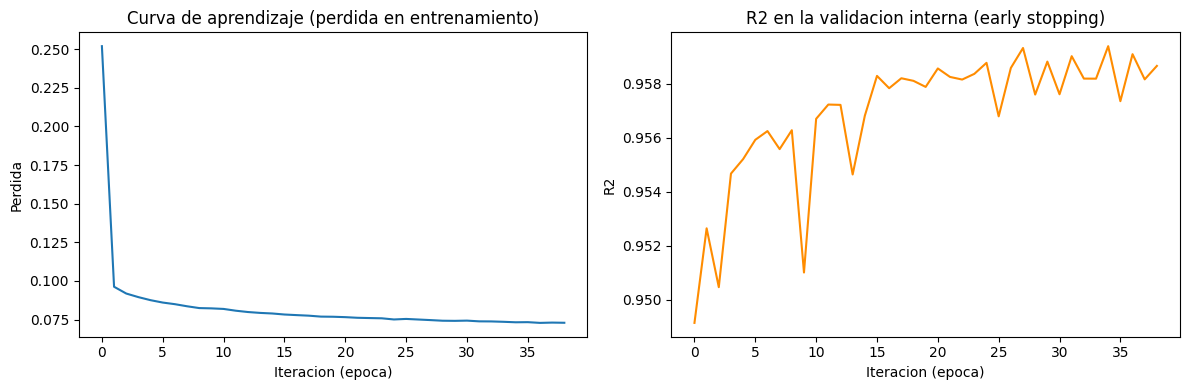

Iteraciones realizadas: 39 | Mejor R2 de validacion interna: 0.9594

                                   WAPE_%  MAE_ha  RMSE_ha     R2
modelo                                                           
Red neuronal (MLP)                 11.429  34.767  383.176  0.935
Base: cosechada = sembrada         11.997  36.495  352.463  0.945
Base: disponible x tasa historica  14.222  43.264  434.936  0.916


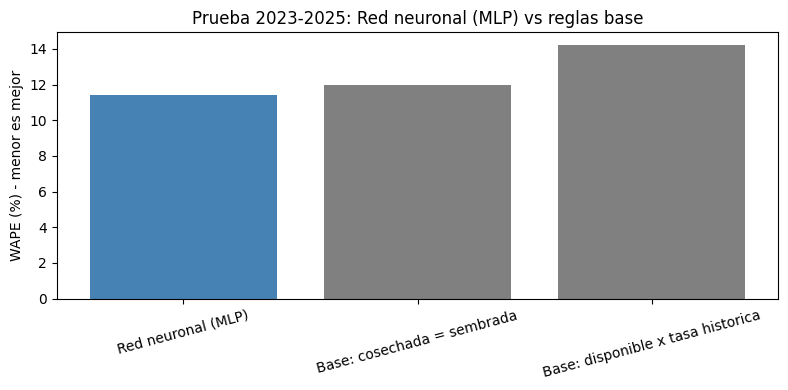


modelo                                              Base: cosechada = sembrada  \
grupo                                                                            
CEREALES                                                                 11.57   
CULTIVOS PARA CONDIMENTOS, BEBIDAS MEDICINALES ...                       10.45   
CULTIVOS TROPICALES TRADICIONALES                                        14.80   
FRUTALES                                                                  9.04   
HORTALIZAS                                                                9.51   
LEGUMINOSAS                                                              10.56   
OLEAGINOSAS                                                               8.46   
RAICES Y TUBERCULOS                                                      18.39   

modelo                                              Base: disponible x tasa historica  \
grupo                                                                                   


In [ ]:
# =========================================================
# PASO M3: Graficos para el informe
# =========================================================
print("PASO M3: Graficos para el informe")

# 1) Curva de aprendizaje de la red final
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
ejes[0].plot(modelo_final.loss_curve_)
ejes[0].set_title("Curva de aprendizaje (perdida en entrenamiento)")
ejes[0].set_xlabel("Iteracion (epoca)")
ejes[0].set_ylabel("Perdida")
ejes[1].plot(modelo_final.validation_scores_, color="darkorange")
ejes[1].set_title("R2 en la validacion interna (early stopping)")
ejes[1].set_xlabel("Iteracion (epoca)")
ejes[1].set_ylabel("R2")
plt.tight_layout()
plt.show()
print("Iteraciones realizadas:", modelo_final.n_iter_, "| Mejor R2 de validacion interna:",
      round(modelo_final.best_validation_score_, 4))

# 2) WAPE total en prueba: red neuronal vs reglas base
total = resultados[resultados["grupo"] == "TOTAL"].set_index("modelo")
print()
print(total[["WAPE_%", "MAE_ha", "RMSE_ha", "R2"]].round(3))

plt.figure(figsize=(8, 4))
colores = ["steelblue" if m == NOMBRE_MODELO else "gray" for m in total.index]
plt.bar(total.index, total["WAPE_%"], color=colores)
plt.ylabel("WAPE (%) - menor es mejor")
plt.title("Prueba 2023-2025: " + NOMBRE_MODELO + " vs reglas base")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

# 3) WAPE por grupo: red neuronal vs "cosechada = sembrada"
por_grupo = resultados[resultados["grupo"] != "TOTAL"].pivot(index="grupo", columns="modelo", values="WAPE_%")
print()
print(por_grupo.round(2))
print("PASO M3: Ejecutado correctamente")
print("-------------------------------")

---
# Notas para el informe

- **Meta:** ganarle a la regla "cosechada = sembrada" (WAPE ~10% en validacion segun el documento del equipo). Referencia de la red sin ajustar `(64, 32)`: ~9,4% en validacion.
- **Si no la supera con claridad**, es un resultado valido: se reporta tal cual y se explica (el 42,5% de las filas cosecha exactamente lo sembrado).
- **Variables que NO se usan** (fuga de informacion): `area_cosechada`, `produccion` y `rendimiento` del mismo anio.
- **Division por anios, nunca aleatoria:** entrenamiento 2007-2021, validacion 2022, prueba 2023-2025 (usada una sola vez).
- **Escalado:** `StandardScaler` ajustado solo con el entrenamiento de cada etapa.
- Archivos guardados en `MiUnidad/EVA/`: `validacion_Red neuronal (MLP).csv`, `resultados_Red neuronal (MLP).csv` y `predicciones_Red neuronal (MLP).csv`.

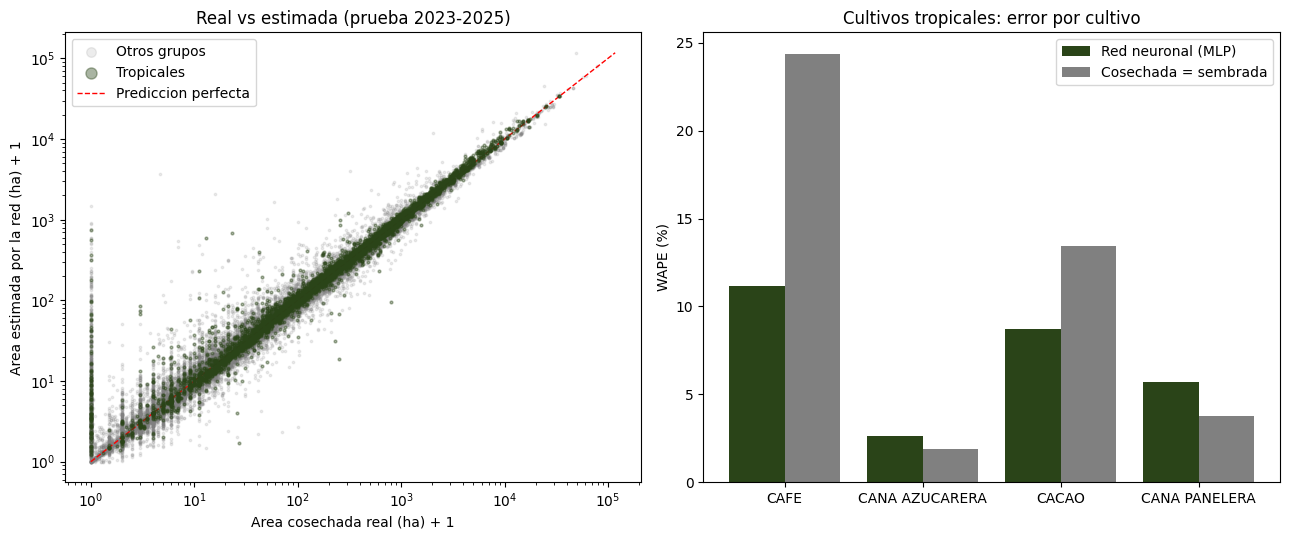

In [ ]:
# =========================================================
# GRAFICAS EXTRA: real vs estimada y error por cultivo (tropicales)
# =========================================================
real = prueba["area_cosechada"].values
estimada = np.asarray(estimada_prueba)
es_trop = (prueba["grupo"] == "CULTIVOS TROPICALES TRADICIONALES").values

fig, ejes = plt.subplots(1, 2, figsize=(13, 5.5))

# A) Real vs estimada (escala log): cuanto mas cerca de la diagonal, mejor
ejes[0].scatter(real[~es_trop] + 1, estimada[~es_trop] + 1, s=3, alpha=0.15, color="gray", label="Otros grupos")
ejes[0].scatter(real[es_trop] + 1, estimada[es_trop] + 1, s=4, alpha=0.4, color="#2A4418", label="Tropicales", zorder=3)
tope = max(real.max(), estimada.max()) + 1
ejes[0].plot([1, tope], [1, tope], "r--", linewidth=1, label="Prediccion perfecta")
ejes[0].set_xscale("log"); ejes[0].set_yscale("log")
ejes[0].set_xlabel("Area cosechada real (ha) + 1"); ejes[0].set_ylabel("Area estimada por la red (ha) + 1")
ejes[0].set_title("Real vs estimada (prueba 2023-2025)")
ejes[0].legend(markerscale=4)

# B) WAPE por cultivo en tropicales: red vs regla "cosechada = sembrada"
t = prueba[es_trop]
est_t = estimada[es_trop]
top = t.groupby("cultivo")["area_cosechada"].sum().nlargest(4).index
nombres, wape_red, wape_regla = [], [], []
for cultivo in top:
    m = (t["cultivo"] == cultivo).values
    nombres.append(cultivo)
    wape_red.append(metricas(t["area_cosechada"].values[m], est_t[m])["WAPE_%"])
    wape_regla.append(metricas(t["area_cosechada"].values[m], t["area_sembrada"].values[m])["WAPE_%"])
x = np.arange(len(nombres))
ejes[1].bar(x - 0.2, wape_red, 0.4, label="Red neuronal (MLP)", color="#2A4418")
ejes[1].bar(x + 0.2, wape_regla, 0.4, label="Cosechada = sembrada", color="gray")
ejes[1].set_xticks(x); ejes[1].set_xticklabels(nombres)
ejes[1].set_ylabel("WAPE (%)"); ejes[1].set_title("Cultivos tropicales: error por cultivo"); ejes[1].legend()
plt.tight_layout()
plt.show()